In [1]:
import sys, subprocess, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo_root = subprocess.run(["git", "rev-parse", "--show-toplevel"],
                           capture_output=True, text=True).stdout.strip()
sys.path.insert(0, repo_root)
from viz_style import set_style, stacked_pct_bar, save_fig, OUTCOME_COLORS, TEXT_SECONDARY

set_style()
COUNTY = "plymouth"
FIG_DIR = os.path.join(repo_root, "figures", COUNTY)
os.makedirs(FIG_DIR, exist_ok=True)

BASE = "/Users/parin/Desktop/prosecutor explorer/plymouth"
plymouth_charges = pd.read_parquet(f"{BASE}/plymouth-charges-enriched.parquet")
plymouth_extras = pd.read_parquet(f"{BASE}/plymouth-extras.parquet")

KEY = ["case_id", "charge_count_number"]
ch = plymouth_charges.drop_duplicates().copy()
ex = plymouth_extras.drop_duplicates(subset=KEY).copy()
ch["charge_count_number"] = ch.charge_count_number.astype("Int64")
ex["charge_count_number"] = ex.charge_count_number.astype("Int64")

df = ch.merge(ex[KEY + ["data_quality_tier", "universal_outcome",
                        "charge_type_description", "sentence_type_description"]],
              on=KEY, how="left", validate="m:1")
print(len(ch), "->", len(df))

938155 -> 938155


In [2]:
YEARS = (2017, 2024)
MISSING_MAX = 0.20
MIN_CELL = 30
EVENTS = {"MA CJ reform act": "2018-04-13", "COVID court closures": "2020-03-16"}
DEF_COL = "def_filled"

def pct(x): return (100 * x).round(1)
def share(s):
    t = s.value_counts(dropna=False)
    return pd.DataFrame({"n": t, "pct": pct(t / t.sum())})
def rate_by(frame, flag, by):
    t = frame.assign(f=np.asarray(flag)).groupby(by, observed=True).f.agg(n="size", k="sum")
    t["pct"] = pct(t.k / t.n)
    return t

In [3]:
bad = (df.disposition_date < "1986-01-01") | (df.disposition_date > pd.Timestamp.today())
df.loc[bad, "disposition_date"] = pd.NaT

# case key: fill null defendant_id from the case's single known id; split multi-defendant dockets
g = df.groupby("case_id").defendant_id
n_ids = g.nunique()
df["def_filled"] = df.defendant_id.fillna(df.case_id.map(g.first().where(n_ids.eq(1))))
df["case_key"] = df.case_id + "|" + df.def_filled.fillna("UNK")

DISPO_MAP = {
    "DM": "dismissal", "NP": "dismissal", "NO": "dismissal", "NB": "dismissal", "DG": "dismissal", "D$": "dismissal",
    "DY": "declined", "DP": "declined", "NY": "declined",                 # pre-arraignment = declination proxy
    "DD": "diversion", "DC": "diversion", "PB": "diversion",
    "GP": "plea", "PF": "plea", "GL": "plea", "PL": "plea", "NC": "plea",
    "CW": "cwof",
    "GF": "trial_conviction", "GI": "trial_conviction", "VF": "trial_conviction", "FL": "trial_conviction",
    "NG": "acquittal", "DV": "acquittal", "NGI": "acquittal",
    "NR": "civil", "RF": "civil", "R$": "civil",
    "TF": "other", "FI": "other", "BO": "other", "RM": "other", "AW": "other",
    "AF": "other", "IN": "other", "NI": "other", "CC": "other",
}
LESSER_CODES = {"GL", "PL", "FL"}

df["outcome"] = df.disposition_code.map(DISPO_MAP)
df.loc[df.disposition_code.isna(), "outcome"] = "pending"
print("unmapped codes:", df.loc[df.outcome.isna(), "disposition_code"].value_counts().to_dict())
df["outcome"] = df.outcome.fillna("other")
df["lesser"] = df.disposition_code.isin(LESSER_CODES)

# severity: charge_category, backfilled from the enrichment degree fields
DEG_MAP = {"F": "F", "Felony": "F", "M+": "M+", "MP": "M+", "M-": "M-", "MM": "M-",
           "Misd.": "M", "CM": "CM", "CI": "CM", "Civil": "CM"}
df["sev_cat"] = df.charge_category
for col in ("mc_degree", "degree", "sc_degree"):
    df["sev_cat"] = df.sev_cat.fillna(df[col].map(DEG_MAP))

df["placeholder"] = df.charge_code.isin(["666666", "999999"])
df["is_civil"] = (df.sev_cat.eq("CM").fillna(False)
                  | df.charge_type_description.str.contains("CIVIL", case=False, na=False)
                  | df.charge_description.str.contains(r"\s\*(?:\s|$)", na=False)
                  | df.outcome.eq("civil"))
df["sev_rank"] = np.where(df.is_civil, 0, df.sev_cat.map({"F": 3, "M+": 2, "M": 1.5, "M-": 1}).fillna(0.5))
df["sev_class"] = np.select(
    [df.is_civil, df.sev_cat.eq("F").fillna(False), df.sev_cat.isin(["M+", "M", "M-"])],
    ["Civil", "Felony", "Misdemeanor"], "Unknown")

df["offense_cat"] = np.where(df.placeholder, "Other/Unknown", df.offense_group)
df["race"] = df.defendant_race.fillna("Unknown").replace({"American Indian/Native": "Other"})
df["sex"] = df.defendant_sex.map({"Male": "Male", "Female": "Female"}).fillna("Unknown")
df["pend"] = df.outcome.eq("pending")

w = df[df.filing_date.dt.year.between(*YEARS)]
print("source in window:", w.source_prr.value_counts().to_dict())
print("severity unknown in window:", pct(w.sev_class.eq("Unknown").mean()), "%")
print("defendant id missing in window:", pct(w.defendant_id.isna().mean()), "%")
print(df.race.value_counts().to_string())

unmapped codes: {}
source in window: {'R001745-022626': 142072}
severity unknown in window: 0.6 %
defendant id missing in window: 48.6 %
race
White           536413
Black           214916
Unknown         144850
Hispanic         23994
Cape Verdean     12363
Other             3211
Asian             2408


In [4]:
OUTCOME_RANK = {"trial_conviction": 8, "plea": 7, "cwof": 6, "diversion": 5, "acquittal": 4,
                "dismissal": 3, "declined": 2, "other": 1, "pending": 0}

lead = (df.sort_values(["case_key", "sev_rank"], ascending=[True, False])
          .drop_duplicates("case_key").set_index("case_key")
          [[DEF_COL, "sev_rank", "sev_class", "offense_cat", "race", "sex",
            "charge_description", "court_name", "data_quality_tier"]])
agg = df.groupby("case_key").agg(filed=("filing_date", "min"), dispo=("disposition_date", "max"),
                                 n_charges=("case_key", "size"),
                                 all_civil=("is_civil", "all"), any_pending=("pend", "any"))
cr = df[~df.is_civil]
outcome = (cr.assign(r=cr.outcome.map(OUTCOME_RANK)).sort_values("r", ascending=False)
             .drop_duplicates("case_key").set_index("case_key").outcome)

cases_all = lead.join(agg).join(outcome)
cases_all["outcome"] = cases_all.outcome.fillna("civil")
cases_all["any_lesser_plea"] = cases_all.index.isin(cr.loc[cr.outcome.eq("plea") & cr.lesser, "case_key"].unique())
cases_all["year"] = cases_all.filed.dt.year
dd = (cases_all.dispo - cases_all.filed).dt.days
cases_all["days_to_dispo"] = dd.where((dd >= 0) & ~cases_all.any_pending)

# prior record: excludes migration artifacts and null ids (insufficient for ~half the window)
p = cases_all[~cases_all.all_civil & cases_all.data_quality_tier.ne("migration_artifact")
              & cases_all[DEF_COL].notna()].sort_values("filed")
cases_all["prior_cases"] = p.groupby(DEF_COL).cumcount().reindex(cases_all.index)
cases_all["prior_level"] = (pd.cut(cases_all.prior_cases, [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])
                              .astype(object).fillna("Unknown"))

cases = cases_all[cases_all.year.between(*YEARS)]
ch_w = df[df.filing_date.dt.year.between(*YEARS)]
crim = cases[~cases.all_civil & cases.outcome.ne("pending")]
charged = crim[crim.outcome.ne("declined")]
convicted = charged[charged.outcome.isin(["plea", "trial_conviction"])]
print(len(cases), "cases |", len(crim), "criminal disposed |", len(charged), "charged |", len(convicted), "convicted")

58659 cases | 55937 criminal disposed | 55685 charged | 10520 convicted


In [5]:
SENT_MAP = {
    "Prison Sentence - Committed": "Incarceration", "Prison Sentence - Concurrent": "Incarceration",
    "Prison Sentence - On and After": "Incarceration", "Prison Sentence - Consecutive": "Incarceration",
    "Prison Sentence - Life without Parole": "Incarceration", "Prison Sentence - Life with Parole": "Incarceration",
    "Prison/Probation - Split Sentence": "Incarceration",
    "Prison - DYS until 18th Birthday": "Incarceration", "Prison - DYS until 19th Birthday": "Incarceration",
    "Prison - DYS until 21st Birthday": "Incarceration", "Prison - DYS until Age 21, then HOC suspended": "Incarceration",
    "Suspended Prison Sentence": "Probation (suspended)", "Suspended until 18th Birthday": "Probation (suspended)",
    "Suspended until 21st Birthday": "Probation (suspended)", "Suspended Sentence On & After": "Probation (suspended)",
    "Probation  (see Probation tab)": "Probation", "Probation (Recommended)": "Probation",
    "Probation until 18th Birthday": "Probation", "Probation until 19th Birthday": "Probation",
    "Fined (Fines & Surfines)": "Fine/other", "Court Costs  (see Costs/Victim tab)": "Fine/other",
    "Restitution  (see Costs/Victim tab)": "Fine/other", "Community Service": "Fine/other",
    "Special Program": "Fine/other",
    "Filed": "Filed (no sentence)",
    "Cont'd w/o Finding (see Probation tab)": "CWOF", "C.W.O.F. (Recommended)": "CWOF",
}
conv_all = df[df.outcome.isin(["plea", "trial_conviction"]) & ~df.is_civil].copy()
conv_all["sent"] = conv_all.sentence_type_description.map(SENT_MAP)
conv_all.loc[conv_all.sentence_type_description.isna(), "sent"] = "Missing"
print("unmapped:", conv_all.loc[conv_all.sent.isna(), "sentence_type_description"].unique())
conv_all["sent"] = conv_all.sent.fillna("Other")

cv_w = conv_all[conv_all.filing_date.dt.year.between(*YEARS)]
sent_missing = cv_w.sent.eq("Missing").mean()
HAS_INCARC = sent_missing <= MISSING_MAX
print(f"sentence missing among convictions: {100 * sent_missing:.1f}% -> HAS_INCARC={HAS_INCARC}")
print(cv_w.sent.value_counts().to_string())

rank = {"Incarceration": 6, "Probation (suspended)": 5, "Probation": 5, "Fine/other": 4,
        "CWOF": 3, "Filed (no sentence)": 2, "Other": 1, "Missing": 0}
case_sent = (conv_all.assign(r=conv_all.sent.map(rank)).sort_values("r", ascending=False)
                     .drop_duplicates("case_key").set_index("case_key").sent)

unmapped: []
sentence missing among convictions: 84.0% -> HAS_INCARC=False
sent
Missing                  16627
Incarceration             1576
Probation                  876
Probation (suspended)      375
Filed (no sentence)        180
Fine/other                 142
CWOF                        17


In [6]:
yr = ch_w.filing_date.dt.year
groups = [
    ({"defendant_id": ch_w.defendant_id.isna(), "filing_date": ch_w.filing_date.isna(),
      "disposition_date": ch_w.disposition_date.isna(),
      "charge_code": ch_w.charge_code.isna() | ch_w.placeholder,
      "disposition_code": ch_w.disposition_code.isna(),
      "race": ch_w.race.eq("Unknown"), "sex": ch_w.sex.eq("Unknown"),
      "court": ch_w.court_name.isna(), "severity": ch_w.sev_class.eq("Unknown"),
      "offense_group": ch_w.offense_cat.eq("Other/Unknown")}, yr),
    ({"sentence_type (convictions)": cv_w.sent.eq("Missing")}, cv_w.filing_date.dt.year),
]
rows = []
for checks, yrs in groups:
    for k, miss in checks.items():
        by_year = (~miss).groupby(yrs).mean()
        rows.append(dict(field=k, pct_missing=pct(miss.mean()),
                         years_available=",".join(str(int(y)) for y, v in by_year.items() if v > 0),
                         status="ok" if miss.mean() <= MISSING_MAX else "insufficient data"))
rows += [dict(field=k, pct_missing=100.0, years_available="", status=f"insufficient data ({why})")
         for k, why in [("sentence_length", "impsd_* columns 100% null"),
                        ("dob/age", "not delivered"), ("bail/detention", "not delivered")]]
coverage = pd.DataFrame(rows)
coverage

,field,pct_missing,years_available,status
0,defendant_id,48.6,"2017,2018,2019,2020,2021",insufficient data
1,filing_date,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
2,disposition_date,4.7,"2017,2018,2019,2020,2021,2022,2023,2024",ok
3,charge_code,0.1,"2017,2018,2019,2020,2021,2022,2023,2024",ok
4,disposition_code,4.5,"2017,2018,2019,2020,2021,2022,2023,2024",ok
5,race,5.8,"2017,2018,2019,2020,2021,2022,2023,2024",ok
6,sex,0.4,"2017,2018,2019,2020,2021,2022,2023,2024",ok
7,court,0.0,"2017,2018,2019,2020,2021,2022,2023,2024",ok
8,severity,0.6,"2017,2018,2019,2020,2021,2022,2023,2024",ok
9,offense_group,1.1,"2017,2018,2019,2020,2021,2022,2023,2024",ok


In [7]:
w_cases = cases[~cases.all_civil]
print(pd.crosstab(w_cases.court_name, w_cases.year))
print(cases_all[~cases_all.all_civil].groupby("year").size().loc[2012:2024])   # WADADAM vs PRR transition

year                     2017.0  2018.0  2019.0  2020.0  2021.0  2022.0  \
court_name                                                                
Brockton District Court    3598    3848    3674    2829    2779    2879   
Hingham District Court      892     836     869     536     584     553   
Plymouth District Court    1851    1826    1890    1634    1742    1717   
Superior Court              275     329     281       1       0       0   
Wareham District Court     1852    1876    1886    1067    1234    1555   

year                     2023.0  2024.0  
court_name                               
Brockton District Court    3157    3232  
Hingham District Court      633     656  
Plymouth District Court    1579    1588  
Superior Court                0       0  
Wareham District Court     1459    1357  
year
2012.0    12621
2013.0    12281
2014.0    11663
2015.0    11485
2016.0    10609
2017.0     8468
2018.0     8715
2019.0     8600
2020.0     6067
2021.0     6339
2022.0     6704

In [8]:
DISTRICT_ONLY = True
if DISTRICT_ONLY:
    cases = cases[cases.court_name.str.contains("District", na=False)]
    ch_w = ch_w[ch_w.court_name.str.contains("District", na=False)]

# Q1-Q8 analysis (Plymouth)
Same questions, definitions, outcome buckets, and chart style as Worcester (shared `viz_style.py`).

**Plymouth differences**
- One charges file (open cases included) plus an extras file.
- District courts only: Superior Court records stop after 2020.
- A declination proxy exists (pre-arraignment dismissals). It is folded into **Dismissal** for the shared outcome buckets and reported separately.
- No bail data (Q5 unavailable).
- Sentence type is 84% missing among convictions (Q4 insufficient data).
- Defendant IDs are 48.6% missing in 2017-2024 and only present through 2021, so Q8 is **insufficient data** under the 20% rule. A supplementary analysis on the subset with known IDs is included but should not be compared across counties.

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm

EXCLUDE = {"Motor Vehicle"}          # minor traffic; add "OUI/DUI" if the client wants all MV offenses out
# Map Plymouth outcomes onto the shared buckets (Trial Conviction and Plea kept separate)
OUTCOMES = ["Trial Conviction", "Plea", "CWOF", "Diversion", "Acquittal", "Dismissal", "Other"]
REP = {"trial_conviction": "Trial Conviction", "plea": "Plea", "cwof": "CWOF",
       "diversion": "Diversion", "acquittal": "Acquittal", "dismissal": "Dismissal",
       "declined": "Dismissal",   # pre-arraignment dismissal (declination proxy) counts as dismissal
       "other": "Other"}
RACES = ["White", "Black", "Hispanic", "Cape Verdean", "Asian", "Other", "Unknown"]

def events(ax):
    for lbl, d in EVENTS.items():
        t = pd.Timestamp(d); x = t.year + (t.dayofyear - 1) / 365
        ax.axvline(x, color="grey", ls="--", lw=1)
        ax.text(x, ax.get_ylim()[1], f" {lbl}", fontsize=8, va="top", color="grey")

def case_traits(d):
    """traffic-only flag + lead offense (known offenses beat traffic and Other/Unknown)"""
    x = d.assign(ex=d.offense_cat.isin(EXCLUDE),
                 unk=d.offense_cat.fillna("Other/Unknown").eq("Other/Unknown"),
                 cc=pd.to_numeric(d.charge_count_number, errors="coerce"))
    traffic_only = x.groupby("case_key").ex.all()
    lead = (x.sort_values(["case_key", "ex", "unk", "sev_rank", "cc"],
                          ascending=[True, True, True, False, True])
              .drop_duplicates("case_key").set_index("case_key").offense_cat.fillna("Other/Unknown"))
    return traffic_only, lead

def clean(c, d):
    t, lead = case_traits(d)
    c = c.assign(traffic_only=t.reindex(c.index).fillna(False).astype(bool),
                 offense_cat=lead.reindex(c.index))
    c = c[~c.all_civil & ~c.traffic_only & c.year.notna()]
    return c.assign(year=c.year.astype(int))

cs = clean(cases, df)                    # in window, district courts, open cases included
done = cs[~cs.any_pending].assign(rep=lambda x: x.outcome.replace(REP))
done["declined"] = done.outcome.eq("declined")
done["dismissed"] = done.rep.eq("Dismissal")
done["convicted"] = done.rep.isin(["Trial Conviction", "Plea"])
conv = done[done.outcome.isin(["plea", "trial_conviction"])].copy()
conv["sent"] = (case_sent.reindex(conv.index)
                .replace({"Probation (suspended)": "Probation"}).fillna("Missing"))
known = conv[conv.sent.ne("Missing")]
print(f"{len(cs):,} cases | {len(done):,} disposed | {len(conv):,} convicted | {len(known):,} with a sentence")

52,302 cases | 50,025 disposed | 9,008 convicted | 1,480 with a sentence


In [10]:
# check: do Plymouth's "guilty" codes separate pleas from trial verdicts?
desc_col = next((c for c in df.columns if "disposition" in c and "desc" in c), "disposition_code")
codes = (df[~df.is_civil & df.outcome.isin(["plea", "trial_conviction", "acquittal", "declined"])]
         .groupby(["outcome", "disposition_code"])
         .agg(n=("case_key", "size"),
              desc=(desc_col, lambda s: s.mode().iat[0] if s.notna().any() else None))
         .sort_values("n", ascending=False))
display(codes)

n  \
outcome          disposition_code           
plea             GP                218320   
acquittal        NG                 32946   
trial_conviction GF                 24001   
                 GI                 18790   
plea             PF                 11616   
                 GL                  2087   
declined         DY                  1175   
acquittal        DV                  1027   
declined         DP                   830   
trial_conviction VF                   555   
                 FL                   495   
plea             PL                   471   
declined         NY                   217   
plea             NC                     7   
acquittal        NGI                    3   

                                                                       desc  
outcome          disposition_code                                            
plea             GP                                             Guilty Plea  
acquittal        NG                              Not Guilty Finding/Verdict  
trial_conviction GF                                  Guilty Finding/Verdict  
                 GI                          Guilty Finding/Verdict - Filed  
plea             PF                                     Guilty Plea - Filed  
                 GL                             Guilty Plea - Lesser Charge  
declined         DY                        Dismissed - Pre-Arraign. (Youth)  
acquittal        DV                  Directed Verdict/Finding of Not Guilty  
declined         DP                Dismissed - Pre-Arraign. (non-Diversion)  
trial_conviction VF                          Guilty Finding/Verdict - Filed  
                 FL                          Guilty Finding - Lesser Charge  
plea             PL                             Guilty Plea - Lesser Charge  
declined         NY                           Nolle Prosequi - Pre-Arraign.  
plea             NC                                     Nolo Contendre Plea  
acquittal        NGI                       Not Guilty by Reason of Insanity

## Standardized Case Table
Every chart below is drawn by the shared `county_charts.py` from this one table, so all counties measure the same things the same way and save figures under the same names.

| Column | Definition |
|---|---|
| `year` | filing year, 2017-2024 |
| `outcome` | most severe outcome across charges (shared buckets); pending cases excluded |
| `offense` | offense category of the most serious charge (lead charge if no severity field) |
| `court`, `race`, `sex` | from the most serious / lead charge; Unknown kept |
| `days` | filing to disposition; negative intervals set to missing |
| `prior_record` | defendant's cases filed in the previous 3 years: 0 / 1-2 / 3+ (Unknown if no defendant ID) |

In [11]:
from county_charts import (check_std, prior_record_3yr, plot_volume, plot_per_capita,
                           plot_outcomes, plot_time, plot_time_by_year, rate_table,
                           plot_rates, plot_q8_heatmap, MIN_CELL as STD_MIN_CELL)

vol = cs.groupby("year").size()
vol.index = vol.index.astype(int)

# prior record: non-civil, non-traffic-only cases, any year, 3-year lookback
traffic_all, _ = case_traits(df)
not_traffic = ~cases_all.index.to_series().map(traffic_all).fillna(False).astype(bool)
ok = not_traffic.values & ~cases_all["all_civil"].values & cases_all["data_quality_tier"].ne("migration_artifact").values
hist = pd.DataFrame({"person": cases_all.loc[ok, DEF_COL], "filing_date": cases_all.loc[ok, "filed"]})
prior = prior_record_3yr(hist)

std = pd.DataFrame({
    "case_key": done.index.values,
    "year": done["year"].astype(int).values,
    "outcome": done["rep"].values,
    "offense": done["offense_cat"].values,
    "court": done["court_name"].values,
    "race": done["race"].values,
    "sex": done["sex"].values,
    "days": done["days_to_dispo"].values,
})
std["prior_record"] = std["case_key"].map(prior).fillna("Unknown")
std = check_std(std)
print(f"{len(std):,} disposed cases | valid interval: {std['days'].notna().mean():.1%} | "
      f"prior record known: {std['prior_record'].ne('Unknown').mean():.1%}")

50,025 disposed cases | valid interval: 98.5% | prior record known: 51.8%


## Q1 + Q2 > Volume & Per Capita

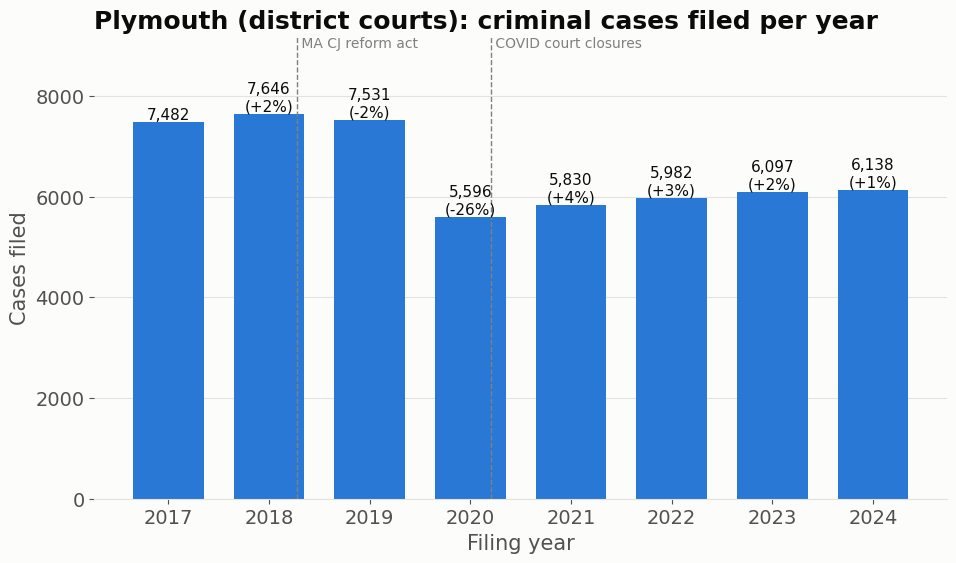

,cases,pct_change_yoy,pct_change_vs_2017,disposed_share
year,,,,
2017,7482,NaN,0.0,96.4
2018,7646,2.2,2.2,97.3
2019,7531,-1.5,0.7,97.0
2020,5596,-25.7,-25.2,95.9
2021,5830,4.2,-22.1,96.2
2022,5982,2.6,-20.0,96.0
2023,6097,1.9,-18.5,94.6
2024,6138,0.7,-18.0,90.8


Q2: fill in annual population for every year to compute per-capita rates.


,n,pct
offense_cat,,
Domestic Violence,10841,20.7
OUI/DUI,7788,14.9
Larceny/Theft,5986,11.4
Assault & Battery,5331,10.2
Disorderly/Public Order,4917,9.4


Other/Unknown: 0.6% of cases


In [12]:
POP = {  # annual Plymouth County population estimates (Census PEP)
    2017: None, 2018: None, 2019: None, 2020: None,
    2021: None, 2022: None, 2023: None, 2024: None,
}
q1 = plot_volume(vol, COUNTY, f"{FIG_DIR}/{COUNTY}_q1_volume.png", scope="district courts")
q1["disposed_share"] = pct(done.groupby("year").size() / vol)
display(q1)
plot_per_capita(vol, POP, COUNTY, f"{FIG_DIR}/{COUNTY}_q2_per_capita.png", scope="district courts")

top = share(cs.offense_cat)
display(top.drop("Other/Unknown", errors="ignore").head(5))
print(f"Other/Unknown: {top.pct.get('Other/Unknown', 0)}% of cases")

**How this was calculated**
- **Unit:** criminal cases (case ID × defendant), open cases included
- **Filters:** district courts only (Superior Court records stop after 2020); civil-only and traffic-only cases excluded
- **Date field:** filing date (earliest charge in the case)
- **Per capita:** cases / annual county population × 10,000. Population isn't in the extract; source and vintage to be agreed by the team. Not computed until `POP` is filled in.

## Q3 > Case Outcomes

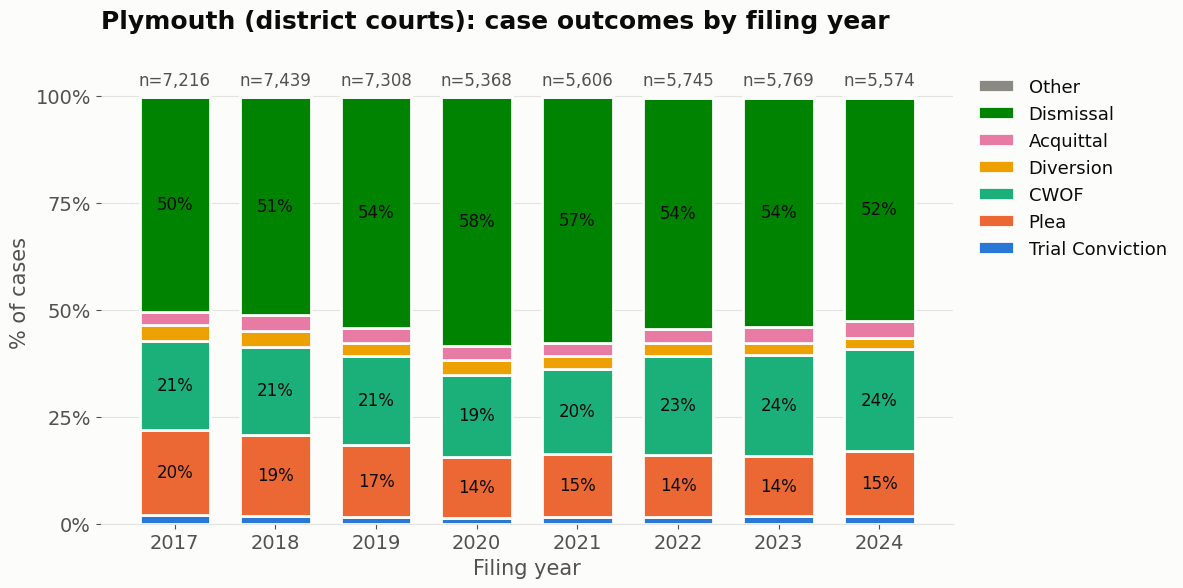

,cases,pct
outcome,,
Dismissal,26800,53.6
CWOF,10717,21.4
Plea,8147,16.3
Acquittal,1726,3.5
Diversion,1591,3.2
Trial Conviction,861,1.7
Other,183,0.4


outcome,Acquittal,CWOF,Dismissal,Diversion,Other,Plea,Trial Conviction
year,,,,,,,
2017,3.1,20.8,50.1,3.6,0.3,19.8,2.1
2018,3.7,20.6,51.0,3.6,0.3,19.0,1.8
2019,3.6,20.8,53.9,3.1,0.3,16.7,1.6
2020,3.2,19.2,58.2,3.4,0.3,14.3,1.4
2021,3.2,20.0,57.4,2.9,0.3,14.8,1.6
2022,3.3,23.1,54.1,3.0,0.4,14.5,1.6
2023,3.7,23.6,53.5,2.9,0.6,14.0,1.8
2024,3.7,23.7,52.3,2.8,0.5,15.3,1.7


Declination proxy (pre-arraignment dismissals, counted in Dismissal): 224 cases (0.4%)
Share of convictions at trial: 9.6%


In [13]:
overall, by_year_pct = plot_outcomes(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q3_outcomes_by_year.png", scope="district courts")
display(overall, by_year_pct)
print(f"Declination proxy (pre-arraignment dismissals, counted in Dismissal): {done.declined.sum():,} cases "
      f"({pct(done.declined.mean())}%)")
print(f"Share of convictions at trial: {pct(done[done.convicted].rep.eq('Trial Conviction').mean())}%")

**How this was calculated**
- **Unit:** disposed criminal cases (case ID × defendant); cases with any pending charge excluded
- **Outcome rule:** most severe outcome across the case's charges (Trial Conviction > Plea > CWOF > Diversion > Acquittal > Dismissal (same order as all counties))
- **Mapping:** GP, PF, GL, PL, NC = Plea. GF, GI, VF, FL = Trial Conviction. CW = CWOF. DD, DC, PB = Diversion. NG, DV, NGI = Acquittal. DM, NP, NO, NB, DG, D$ = Dismissal. DY, DP, NY (pre-arraignment) = Dismissal, reported separately as a declination proxy.
- **Date field:** filing year

**Notes:**
- Plea and trial convictions are now reported separately, per the agreed criteria.
- "Guilty Finding/Verdict" codes (GF, GI) are treated as trial convictions. The share of convictions at trial is printed above; if it is much higher than other counties, check whether some of these follow an admission rather than a trial.
- Recent years include cases still open, so 2023-24 shares are provisional.

## Q4 > Sentencing (insufficient data)

In [14]:
cov = conv.groupby("year").sent.apply(lambda s: pct(s.ne("Missing").mean())).rename("pct_with_sentence")
display(cov.to_frame())
display(share(known.sent))

,pct_with_sentence
year,
2017,89.5
2018,4.0
2019,0.1
2020,0.0
2021,0.0
2022,0.1
2023,0.0
2024,0.0


,n,pct
sent,,
Probation,687,46.4
Incarceration,638,43.1
Fine/other,89,6.0
Filed (no sentence),59,4.0
CWOF,7,0.5


Sentence type is missing for most convictions and only recorded in some years, so Plymouth sentencing rates aren't reported. The table above is for reference only.

## Q5 > Pretrial Detention and Bail
Not available: bail and detention data weren't delivered for Plymouth, so no Q5 charts (`plot_bail` is skipped). Marked **insufficient data**.

## Q6 > Time to Disposition

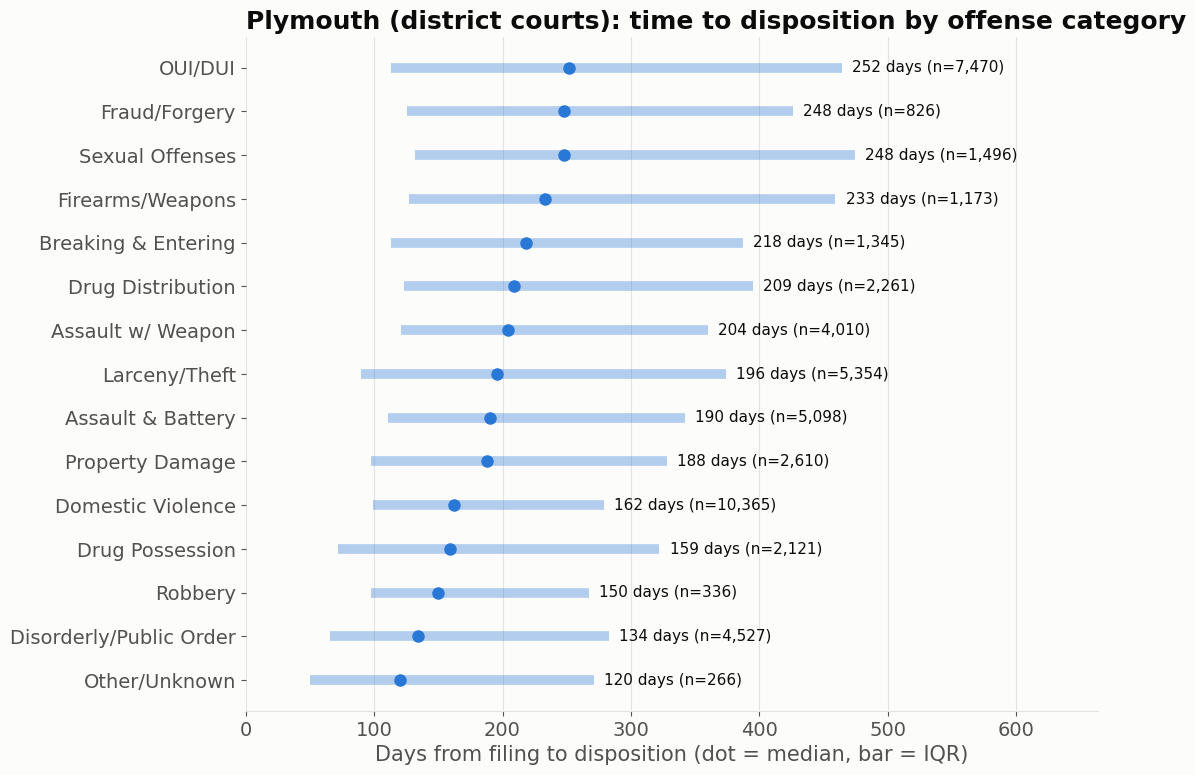

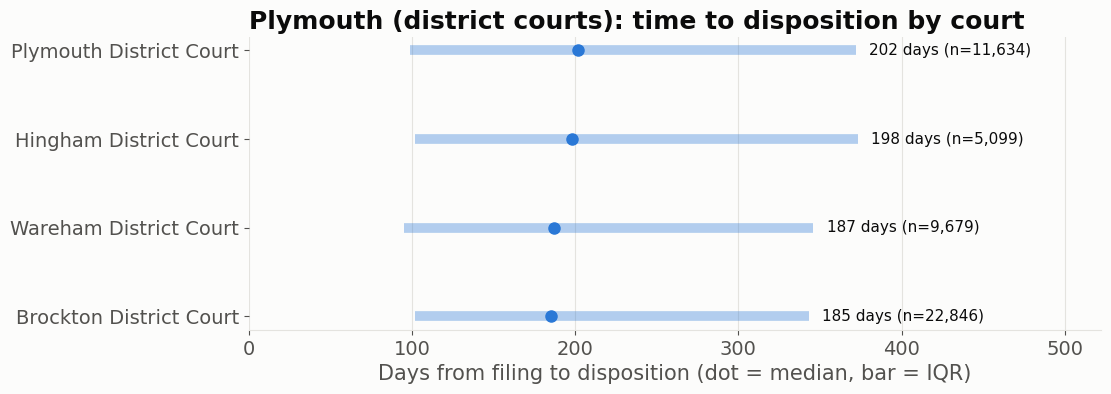

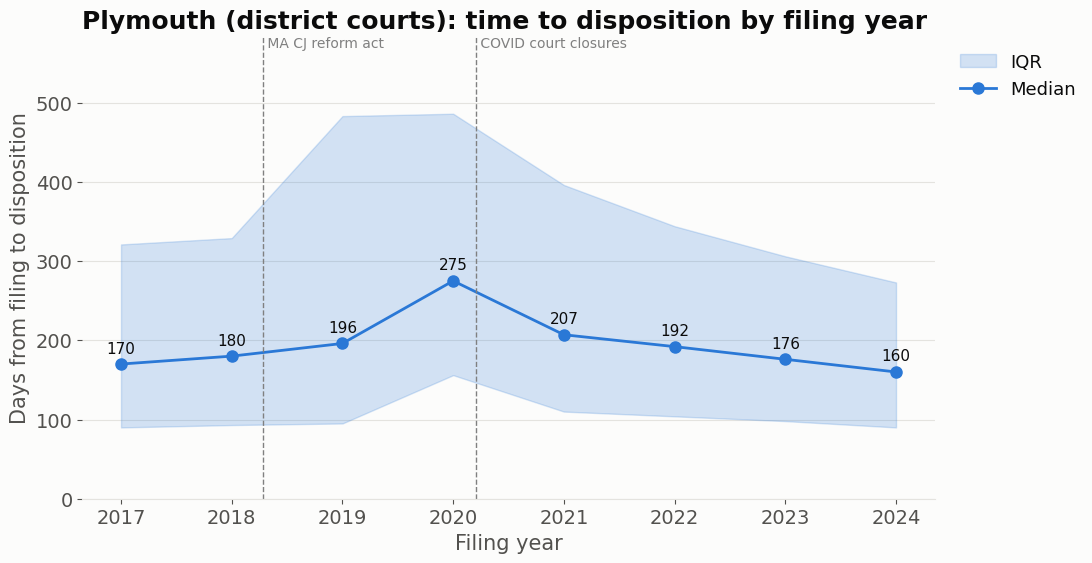

Overall median: 190 days (IQR 100-355)


,n,median,q1,q3
offense,,,,
Assault & Battery,5098,190.0,111.0,342.0
Assault w/ Weapon,4010,204.0,121.0,360.0
Breaking & Entering,1345,218.0,113.0,387.0
Disorderly/Public Order,4527,134.0,66.0,283.0
Domestic Violence,10365,162.0,99.0,279.0
Drug Distribution,2261,209.0,123.0,395.0
Drug Possession,2121,159.0,72.0,322.0
Firearms/Weapons,1173,233.0,127.0,459.0
Fraud/Forgery,826,248.0,126.0,426.0


,n,median,q1,q3
court,,,,
Brockton District Court,22846,185.0,102.0,343.0
Hingham District Court,5099,198.0,102.0,373.0
Plymouth District Court,11634,202.0,99.0,372.0
Wareham District Court,9679,187.0,95.0,346.0


,n,median,q1,q3
year,,,,
2017,7123,170.0,90.0,321.0
2018,7314,180.0,93.0,329.0
2019,7155,196.0,95.0,483.0
2020,5287,275.0,156.0,486.0
2021,5531,207.0,110.0,396.0
2022,5655,192.0,104.0,344.0
2023,5699,176.0,98.0,306.0
2024,5494,160.0,90.0,273.0


,n,median,q1,q3
sev_class,,,,
Felony,24519,194.0,111.0,357.0
Misdemeanor,24692,187.0,90.0,353.0
Unknown,47,120.0,84.5,263.5


In [15]:
t6_offense = plot_time(std, "offense", "offense category", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_offense.png", scope="district courts")
t6_court = plot_time(std, "court", "court", COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_court.png", scope="district courts")
t6_year = plot_time_by_year(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q6_time_by_year.png", scope="district courts")
print(f"Overall median: {std['days'].median():.0f} days "
      f"(IQR {std['days'].quantile(.25):.0f}-{std['days'].quantile(.75):.0f})")
display(t6_offense, t6_court, t6_year)

# Plymouth extra: by felony / misdemeanor (no chart; Worcester has no severity field)
sev = done.assign(days=done.days_to_dispo).dropna(subset=["days"]).groupby("sev_class")["days"]
display(pd.DataFrame({"n": sev.size(), "median": sev.median(),
                      "q1": sev.quantile(.25), "q3": sev.quantile(.75)}).query("n >= @MIN_CELL"))

**How this was calculated**
- **Unit:** disposed cases
- **Interval:** earliest filing date to latest disposition date in the case; negative intervals excluded
- **Charts:** by offense category, by court, and by filing year (dot or line = median, bar or band = IQR)
- **Filters:** groups with fewer than 30 cases hidden

**Note:** pending cases are excluded, so 2023-24 medians are biased low.

## Q7 > Disparities by Race and Sex

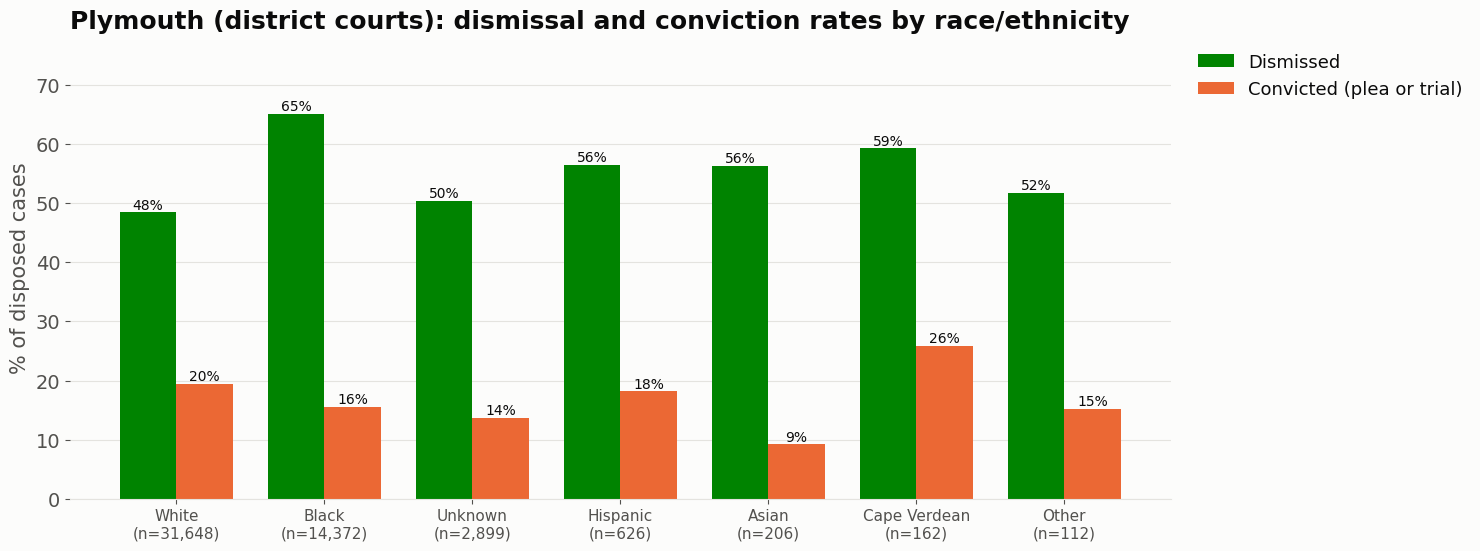

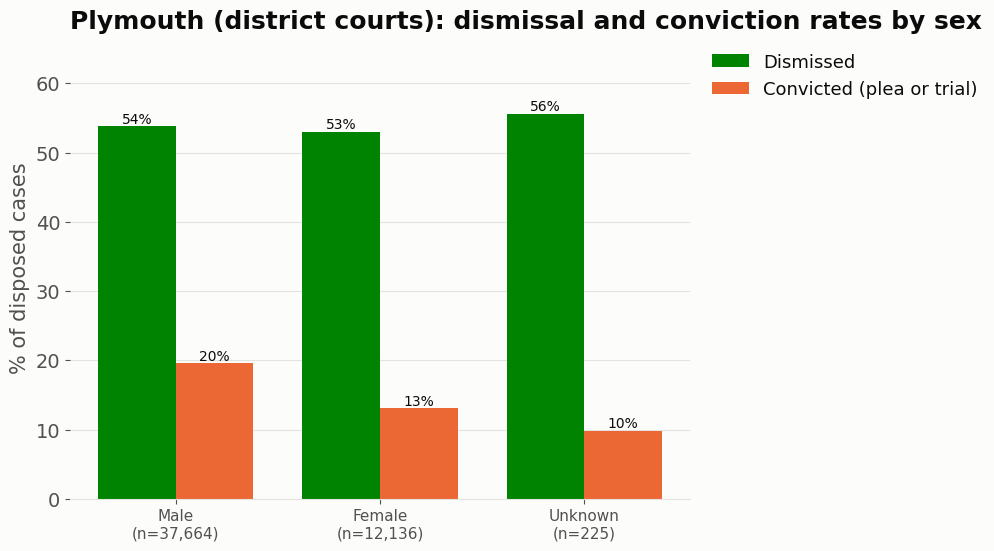

,n,dismissal_pct,dismissal_ratio_vs_White,conviction_pct,conviction_ratio_vs_White
race,,,,,
White,31648,48.5,1.00,19.5,1.00
Black,14372,65.1,1.34,15.6,0.80
Unknown,2899,50.4,1.04,13.7,0.70
Hispanic,626,56.5,1.17,18.2,0.93
Asian,206,56.3,1.16,9.2,0.47
Cape Verdean,162,59.3,1.22,25.9,1.33
Other,112,51.8,1.07,15.2,0.78


,n,dismissal_pct,dismissal_ratio_vs_Male,conviction_pct,conviction_ratio_vs_Male
sex,,,,,
Male,37664,53.8,1.00,19.6,1.00
Female,12136,53.0,0.99,13.1,0.67
Unknown,225,55.6,1.03,9.8,0.50


In [16]:
t7_race = plot_rates(std, "race", "White", "race/ethnicity", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_race.png", scope="district courts")
t7_sex = plot_rates(std, "sex", "Male", "sex", COUNTY, f"{FIG_DIR}/{COUNTY}_q7_rates_by_sex.png", scope="district courts")
display(t7_race, t7_sex)

**How this was calculated**
- **Unit:** disposed cases
- **Rates:** dismissal = Dismissal bucket (including pre-arraignment); conviction = Plea or Trial Conviction (same in every county)
- **Rate ratio:** group rate / reference group rate (White for race, Male for sex)
- **Filters:** groups under 30 cases suppressed; Unknown kept as its own group

**Notes:**
- Incarceration rates are not reported for Plymouth: sentence type is mostly missing (Q4).
- Cape Verdean is reported as its own group, as recorded in the data.
- Declination is only measurable through the pre-arraignment proxy.

## Q8 > Disparities with Controls

**Insufficient data under the agreed 20% rule:** defendant IDs are 48.6% missing in 2017-2024 and only present through 2021, so prior record cannot be measured for most cases.

**Supplementary analysis (not for cross-county comparison):** the cells below use only cases with a known prior record (filing years 2017-2021). They are kept for internal reference.

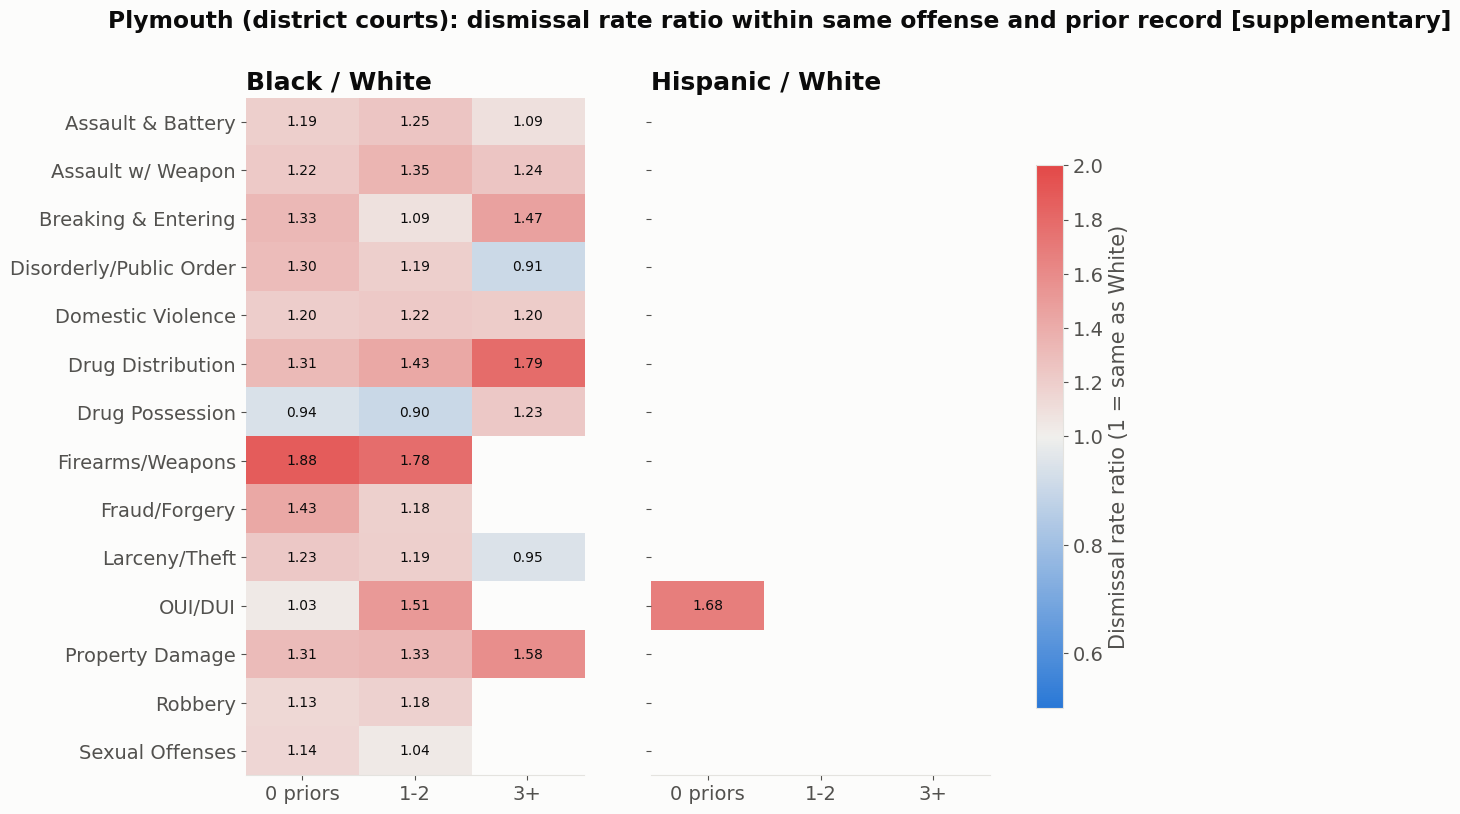

Q8 cases with known prior record: 25,888


race                                  Black  Hispanic  Unknown  White
offense                 prior_record                                 
Assault & Battery       0              75.1       NaN     56.0   63.1
                        1-2            76.3       NaN      NaN   61.1
                        3+             61.5       NaN      NaN   56.6
Assault w/ Weapon       0              77.9       NaN     62.5   63.6
                        1-2            81.8       NaN      NaN   60.6
                        3+             72.4       NaN      NaN   58.2
Breaking & Entering     0              55.8       NaN      NaN   42.1
                        1-2            44.3       NaN      NaN   40.8
                        3+             48.9       NaN      NaN   33.3
Disorderly/Public Order 0              60.6       NaN     43.6   46.5
                        1-2            59.1       NaN      NaN   49.5
                        3+             42.4       NaN      NaN   46.6
Domestic Violence       0              87.8       NaN     81.1   73.1
                        1-2            78.5       NaN     71.1   64.2
                        3+             70.4       NaN      NaN   58.5
Drug Distribution       0              59.4       NaN     65.6   45.2
                        1-2            60.3       NaN      NaN   42.2
                        3+             61.7       NaN      NaN   34.5
Drug Possession         0              39.5       NaN      NaN   41.8
                        1-2            33.3       NaN      NaN   36.9
                        3+             27.5       NaN      NaN   22.3
Firearms/Weapons        0              70.0       NaN      NaN   37.3
                        1-2            74.5       NaN      NaN   41.9
Fraud/Forgery           0              58.2       NaN     45.3   40.8
                        1-2            53.2       NaN      NaN   44.9
                        3+              NaN       NaN      NaN   32.4
Larceny/Theft           0              65.2       NaN     55.0   53.1
                        1-2            55.8       NaN      NaN   46.8
                        3+             32.9       NaN      NaN   34.8
OUI/DUI                 0              15.4      25.0     14.5   14.9
                        1-2            24.5       NaN      NaN   16.2
                        3+              NaN       NaN      NaN   14.7
Other/Unknown           0               NaN       NaN      NaN   65.4
                        1-2             NaN       NaN      NaN   74.2
Property Damage         0              58.8       NaN     50.0   44.9
                        1-2            58.7       NaN      NaN   44.1
                        3+             63.4       NaN      NaN   40.0
Robbery                 0              96.2       NaN      NaN   84.8
                        1-2            84.8       NaN      NaN   71.9
Sexual Offenses         0              68.7       NaN     61.9   60.1
                        1-2            64.4       NaN      NaN   62.0

In [17]:
# Supplementary: same heatmap and definitions as other counties, on the subset with known prior record
q8_rates = plot_q8_heatmap(std, COUNTY, f"{FIG_DIR}/{COUNTY}_q8_dismissal_ratio_heatmap.png",
                           supplementary=True, scope="district courts")
display(q8_rates)

In [18]:
# Supplementary (Plymouth only): logistic model odds ratios, table only
import statsmodels.formula.api as smf
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm

RG = ["White", "Black", "Hispanic", "Cape Verdean"]
CTRL = ["offense_cat", "prior_level", "sev_class", "court_name", "year"]

def race_or(data, controls):
    f = "y ~ C(race, Treatment('White'))" + "".join(f" + C({c})" for c in controls)
    r = smf.logit(f, data=data).fit(disp=0, maxiter=300)
    if not r.mle_retvals["converged"]:
        print("NOT converged:", controls[:1], r.params.abs().sort_values().tail(3).round(1).to_dict())
    ci = np.exp(r.conf_int())
    out = pd.DataFrame({"OR": np.exp(r.params), "lo": ci[0], "hi": ci[1]})
    out = out[out.index.str.startswith("C(race")]
    out.index = out.index.str.extract(r"T\.(.+?)\]")[0].values
    return out.round(2)

d0 = done.assign(prior_level=done.index.map(prior).fillna("Unknown"))   # 3-year lookback
pr = d0[d0.race.isin(RG) & d0.prior_level.ne("Unknown") & d0.sev_class.ne("Unknown")]
print(f"cases with known prior record: {len(pr):,} of {len(done):,} "
      f"({100 * len(pr) / len(done):.0f}%), filing years {pr.year.min()}-{pr.year.max()}")

res = []
for name, flag in [("Dismissal", "dismissed"), ("Conviction", "convicted")]:
    d = pr.assign(y=pr[flag].astype(int))
    d = d[d.groupby("offense_cat").y.transform("size") >= MIN_CELL]
    for label, ctrl in [("Raw", []), ("Adjusted", CTRL)]:
        res.append(race_or(d, ctrl).assign(outcome=name, model=label))
ors = pd.concat(res).rename_axis("race").reset_index()
display(ors.pivot_table(index=["outcome", "race"], columns="model", values="OR")[["Raw", "Adjusted"]])

cases with known prior record: 24,297 of 50,025 (49%), filing years 2017-2021


/Users/parin/Library/Python/3.9/lib/python/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/parin/Library/Python/3.9/lib/python/site-packages/pandas/core/internals/blocks.py:395: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


NOT converged: ['offense_cat'] {'C(offense_cat)[T.Breaking & Entering]': 1.1, 'C(offense_cat)[T.OUI/DUI]': 2.2, 'C(year)[T.2021]': 22.8}
NOT converged: ['offense_cat'] {'C(prior_level)[T.3+]': 1.5, 'Intercept': 2.2, 'C(year)[T.2021]': 18.6}


/Users/parin/Library/Python/3.9/lib/python/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/parin/Library/Python/3.9/lib/python/site-packages/pandas/core/internals/blocks.py:395: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


model                     Raw  Adjusted
outcome    race                        
Conviction Black         0.77      0.85
           Cape Verdean  1.38      1.28
           Hispanic      0.95      0.98
Dismissal  Black         2.06      1.51
           Cape Verdean  1.35      1.22
           Hispanic      1.86      1.98

**How this was calculated (supplementary)**
- **Subset:** cases with a known prior record (defendant IDs exist only through 2021)
- **Prior record:** the defendant's cases filed in the 3 years before this case (same lookback in every county), bucketed 0 / 1-2 / 3+
- **Heatmap:** group dismissal rate / White dismissal rate within the same offense and prior-record cell, same chart as other counties; cells under 30 cases suppressed
- **Odds-ratio table (Plymouth only):** logistic regression with offense category, prior record, felony/misdemeanor, court, and filing year as controls

**Limitation:** insufficient data under the 20% rule; do not compare with other counties.